# Regresión no lineal
**Polinomios · modelos no lineales con fórmula · regresores de machine learning**

Seguimos con el consumo de autos (Auto MPG) de las clases anteriores. Vamos a ver tres caminos cuando la relación
no es una recta: **transformar las variables** (polinomios, splines), **ajustar una fórmula no lineal** (`curve_fit`)
y **dejar que un algoritmo aprenda la forma** (k vecinos, árboles, ensambles y SVR).

Notebook expositiva: ejecutar en orden con **Shift + Enter** en Google Colab.
Se necesita conexión a internet para descargar los datos; no hace falta una GPU.

In [1]:
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.optimize import curve_fit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, SplineTransformer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, r2_score
warnings.filterwarnings("ignore")

## 1. Los datos

Misma preparación que en N04 y N05: descartamos los autos sin potencia, pasamos `origin` a dummies
y reservamos **20 % para prueba**. Para los gráficos usamos una sola variable: la **potencia** (`horsepower`).

In [2]:
autos = sns.load_dataset("mpg").dropna()
datos = pd.get_dummies(autos.drop(columns="name"), columns=["origin"], drop_first=True, dtype=int)
X = datos.drop(columns="mpg")
y = datos["mpg"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

hp = autos[["horsepower"]].values
mpg = autos["mpg"].values
grilla = np.linspace(hp.min(), hp.max(), 300).reshape(-1, 1)
print("Entrenamiento:", X_train.shape, "· Prueba:", X_test.shape)

Entrenamiento: (313, 8) · Prueba: (79, 8)


## 2. Cuando una recta no alcanza

Ajustamos una recta y miramos los **residuos**. Si el modelo fuera adecuado, los residuos serían ruido alrededor de cero.

R² de la recta: 0.606


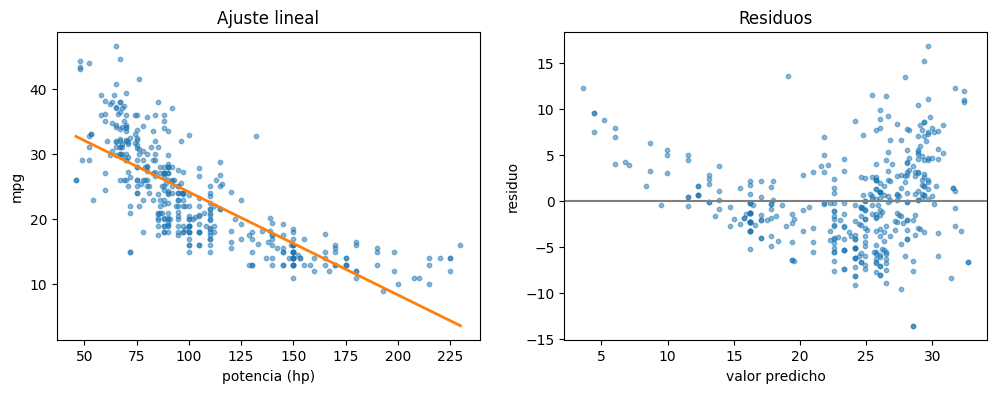

In [3]:
recta = LinearRegression().fit(hp, mpg)
residuos = mpg - recta.predict(hp)
print(f"R² de la recta: {recta.score(hp, mpg):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(hp, mpg, s=10, alpha=0.5)
ax[0].plot(grilla, recta.predict(grilla), color="C1", lw=2)
ax[0].set(xlabel="potencia (hp)", ylabel="mpg", title="Ajuste lineal")
ax[1].scatter(recta.predict(hp), residuos, s=10, alpha=0.5)
ax[1].axhline(0, color="grey")
ax[1].set(xlabel="valor predicho", ylabel="residuo", title="Residuos")
plt.show()

**Lectura:** los residuos tienen forma de **U**: son positivos en los extremos y negativos en el medio.
No es ruido, es una curva que la recta no captura.

## 3. Regresión polinómica

`PolynomialFeatures` agrega x², x³, … como variables nuevas. El modelo sigue siendo **lineal en los coeficientes**,
por eso se ajusta con `LinearRegression`. Escalamos antes, para que los términos de grado alto no tengan valores enormes.

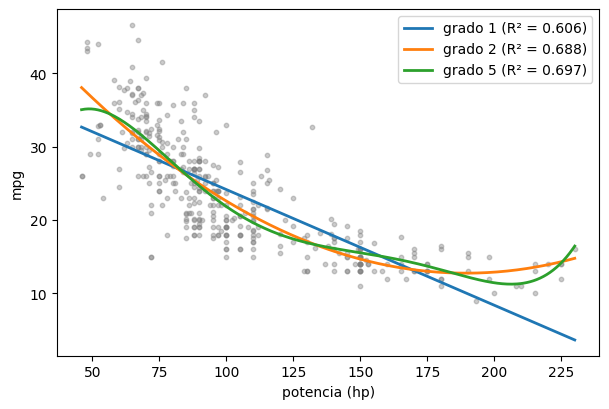

In [4]:
plt.figure(figsize=(7, 4.5))
plt.scatter(hp, mpg, s=10, alpha=0.4, color="grey")
for grado in [1, 2, 5]:
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(grado), LinearRegression()).fit(hp, mpg)
    plt.plot(grilla, modelo.predict(grilla), lw=2, label=f"grado {grado} (R² = {modelo.score(hp, mpg):.3f})")
plt.xlabel("potencia (hp)"); plt.ylabel("mpg"); plt.legend()
plt.show()

### Elegir el grado con validación cruzada

El grado es un **hiperparámetro**. El error de entrenamiento siempre baja al subir el grado; para elegir miramos el de validación cruzada.

,grado,RMSE entrenamiento,RMSE validación
0,1,4.889,4.909
1,2,4.353,4.364
2,3,4.347,4.365
3,4,4.337,4.383
4,5,4.285,4.337
5,6,4.262,4.331
6,7,4.242,4.321
7,8,4.237,4.349
8,9,4.228,4.387
9,10,4.224,4.434


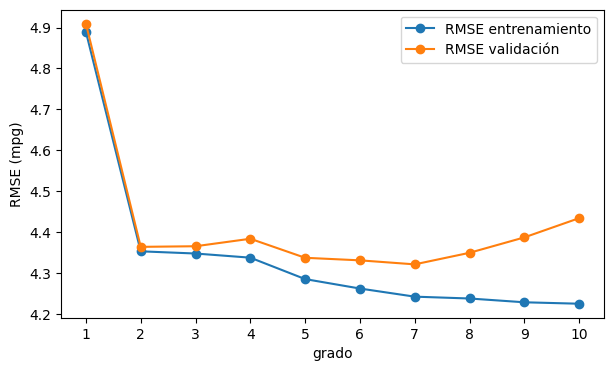

In [5]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
filas = []
for grado in range(1, 11):
    modelo = make_pipeline(StandardScaler(), PolynomialFeatures(grado), LinearRegression())
    r = cross_validate(modelo, hp, mpg, cv=kf, scoring="neg_root_mean_squared_error", return_train_score=True)
    filas.append({"grado": grado, "RMSE entrenamiento": -r["train_score"].mean(), "RMSE validación": -r["test_score"].mean()})
curva = pd.DataFrame(filas)
display(curva.round(3))

curva.plot(x="grado", marker="o", figsize=(7, 4))
plt.ylabel("RMSE (mpg)"); plt.xticks(range(1, 11))
plt.show()

**Lectura:** el salto grande está entre grado 1 y 2. Después el error de validación casi no baja y desde grado 8
empieza a subir: conviene el modelo simple.

### Splines: polinomios por tramos

`SplineTransformer` arma polinomios de grado bajo en tramos, unidos en **nudos**. Son más estables en los bordes.

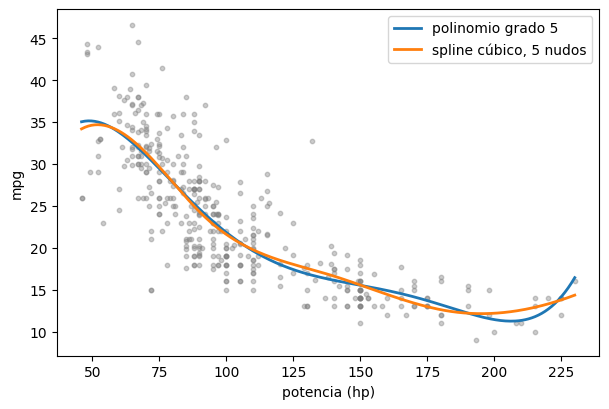

In [6]:
spline = make_pipeline(SplineTransformer(n_knots=5, degree=3), LinearRegression()).fit(hp, mpg)
poli5 = make_pipeline(StandardScaler(), PolynomialFeatures(5), LinearRegression()).fit(hp, mpg)

plt.figure(figsize=(7, 4.5))
plt.scatter(hp, mpg, s=10, alpha=0.4, color="grey")
plt.plot(grilla, poli5.predict(grilla), lw=2, label="polinomio grado 5")
plt.plot(grilla, spline.predict(grilla), lw=2, label="spline cúbico, 5 nudos")
plt.xlabel("potencia (hp)"); plt.ylabel("mpg"); plt.legend()
plt.show()

## 4. Modelos no lineales con fórmula: `curve_fit`

Cuando el fenómeno tiene una fórmula conocida, ajustamos sus parámetros por **mínimos cuadrados no lineales**.
Usamos los datos clásicos de **Puromycin**: velocidad de una reacción enzimática según la concentración del sustrato.
La fórmula es la de Michaelis-Menten: **v = Vmax · x / (K + x)**.

In [7]:
URL = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/datasets/"
puro = pd.read_csv(URL + "Puromycin.csv")
puro = puro[puro["state"] == "treated"]
display(puro.head())

def michaelis(x, vmax, k):
    return vmax * x / (k + x)

# p0: valores iniciales leídos del gráfico (techo ≈ 200, mitad del techo cerca de 0.1)
params, cov = curve_fit(michaelis, puro["conc"], puro["rate"], p0=[200, 0.1])
errores = np.sqrt(np.diag(cov))
print(f"Vmax = {params[0]:.1f} ± {errores[0]:.1f}")
print(f"K    = {params[1]:.3f} ± {errores[1]:.3f}")

,rownames,conc,rate,state
0,1,0.02,76,treated
1,2,0.02,47,treated
2,3,0.06,97,treated
3,4,0.06,107,treated
4,5,0.11,123,treated


Vmax = 212.7 ± 6.9
K    = 0.064 ± 0.008


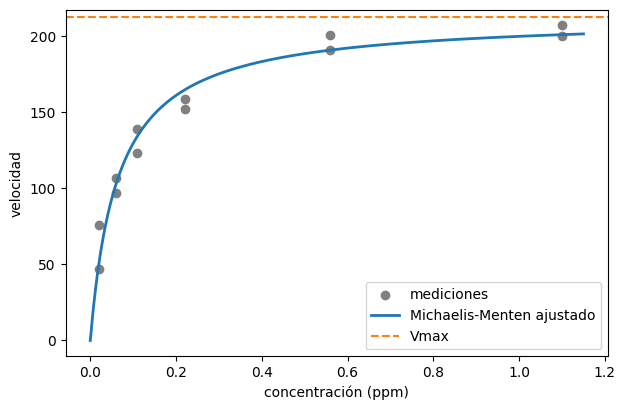

In [8]:
xg = np.linspace(0, 1.15, 200)
plt.figure(figsize=(7, 4.5))
plt.scatter(puro["conc"], puro["rate"], color="grey", label="mediciones")
plt.plot(xg, michaelis(xg, *params), lw=2, label="Michaelis-Menten ajustado")
plt.axhline(params[0], ls="--", color="C1", label="Vmax")
plt.xlabel("concentración (ppm)"); plt.ylabel("velocidad"); plt.legend()
plt.show()

### Los valores iniciales importan

El algoritmo es iterativo y parte de `p0`. Probemos con valores iniciales malos.

In [9]:
for p0 in [[200, 0.1], [1, 1], [200, -0.5]]:
    try:
        p, _ = curve_fit(michaelis, puro["conc"], puro["rate"], p0=p0, maxfev=2000)
        print(f"p0 = {p0} → Vmax = {p[0]:.1f}, K = {p[1]:.3f}")
    except RuntimeError as e:
        print(f"p0 = {p0} → no converge: {e}")

p0 = [200, 0.1] → Vmax = 212.7, K = 0.064
p0 = [1, 1] → Vmax = 212.7, K = 0.064
p0 = [200, -0.5] → Vmax = 26.0, K = -0.490


**Lectura:** con valores iniciales razonables llegamos siempre al mismo resultado; con valores absurdos el algoritmo
puede no converger o terminar en una solución sin sentido. Siempre hay que **graficar** el ajuste.

### Exponencial o logística: la forma decide la extrapolación

Censos de población de EE.UU. de 1790 a 1970 (en millones). Ajustamos las dos fórmulas y miramos qué predicen para 2020.

Techo estimado por la logística: K = 316 millones
Predicción para 2020 → exponencial: 474, logística: 269, real: 331


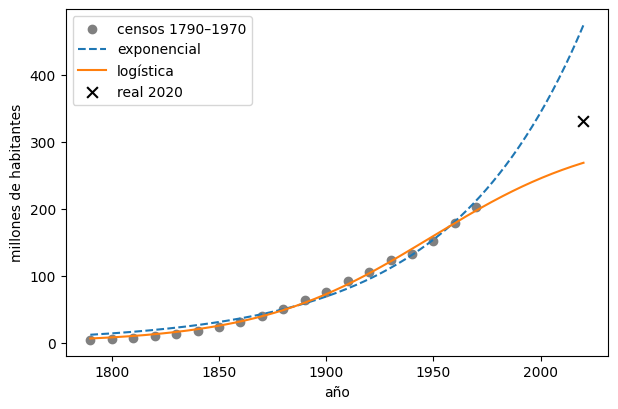

In [10]:
pob = pd.read_csv(URL + "uspop.csv")
t = pob["time"].values - 1790
exponencial = lambda t, a, b: a * np.exp(b * t)
logistica = lambda t, K, a, b: K / (1 + a * np.exp(-b * t))
pe, _ = curve_fit(exponencial, t, pob["value"], p0=[4, 0.03])
pl, _ = curve_fit(logistica, t, pob["value"], p0=[300, 50, 0.03], maxfev=20000)
print(f"Techo estimado por la logística: K = {pl[0]:.0f} millones")
print(f"Predicción para 2020 → exponencial: {exponencial(230, *pe):.0f}, logística: {logistica(230, *pl):.0f}, real: 331")

tg = np.linspace(0, 230, 300)
plt.figure(figsize=(7, 4.5))
plt.scatter(pob["time"], pob["value"], color="grey", label="censos 1790–1970")
plt.plot(tg + 1790, exponencial(tg, *pe), ls="--", label="exponencial")
plt.plot(tg + 1790, logistica(tg, *pl), label="logística")
plt.scatter([2020], [331.4], color="black", marker="x", s=60, label="real 2020")
plt.xlabel("año"); plt.ylabel("millones de habitantes"); plt.legend()
plt.show()

## 5. Regresores de machine learning

Ahora no proponemos ninguna fórmula: el algoritmo aprende la forma. Son los mismos que vimos para clasificar,
en su versión de regresión. Primero los vemos con una sola variable para comparar las curvas.

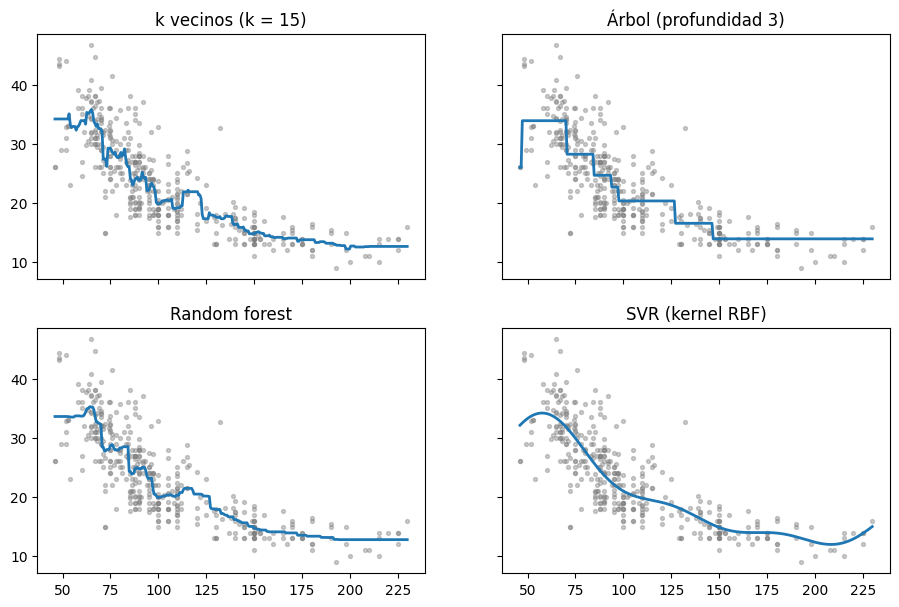

In [11]:
modelos = {
    "k vecinos (k = 15)": KNeighborsRegressor(n_neighbors=15),
    "Árbol (profundidad 3)": DecisionTreeRegressor(max_depth=3, random_state=0),
    "Random forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=10, random_state=0),
    "SVR (kernel RBF)": make_pipeline(StandardScaler(), SVR(C=30, epsilon=1)),
}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (nombre, modelo) in zip(axes.ravel(), modelos.items()):
    modelo.fit(hp, mpg)
    ax.scatter(hp, mpg, s=8, alpha=0.4, color="grey")
    ax.plot(grilla, modelo.predict(grilla), lw=2)
    ax.set_title(nombre)
plt.show()

**Lectura:** KNN da una curva irregular, el árbol una escalera, el random forest suaviza la escalera
y SVR da una curva suave. Ninguno necesitó que le digamos la forma.